In [1]:
import numpy as np
import pripps
from scipy.optimize import minimize
import matplotlib.pyplot as plt

Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')


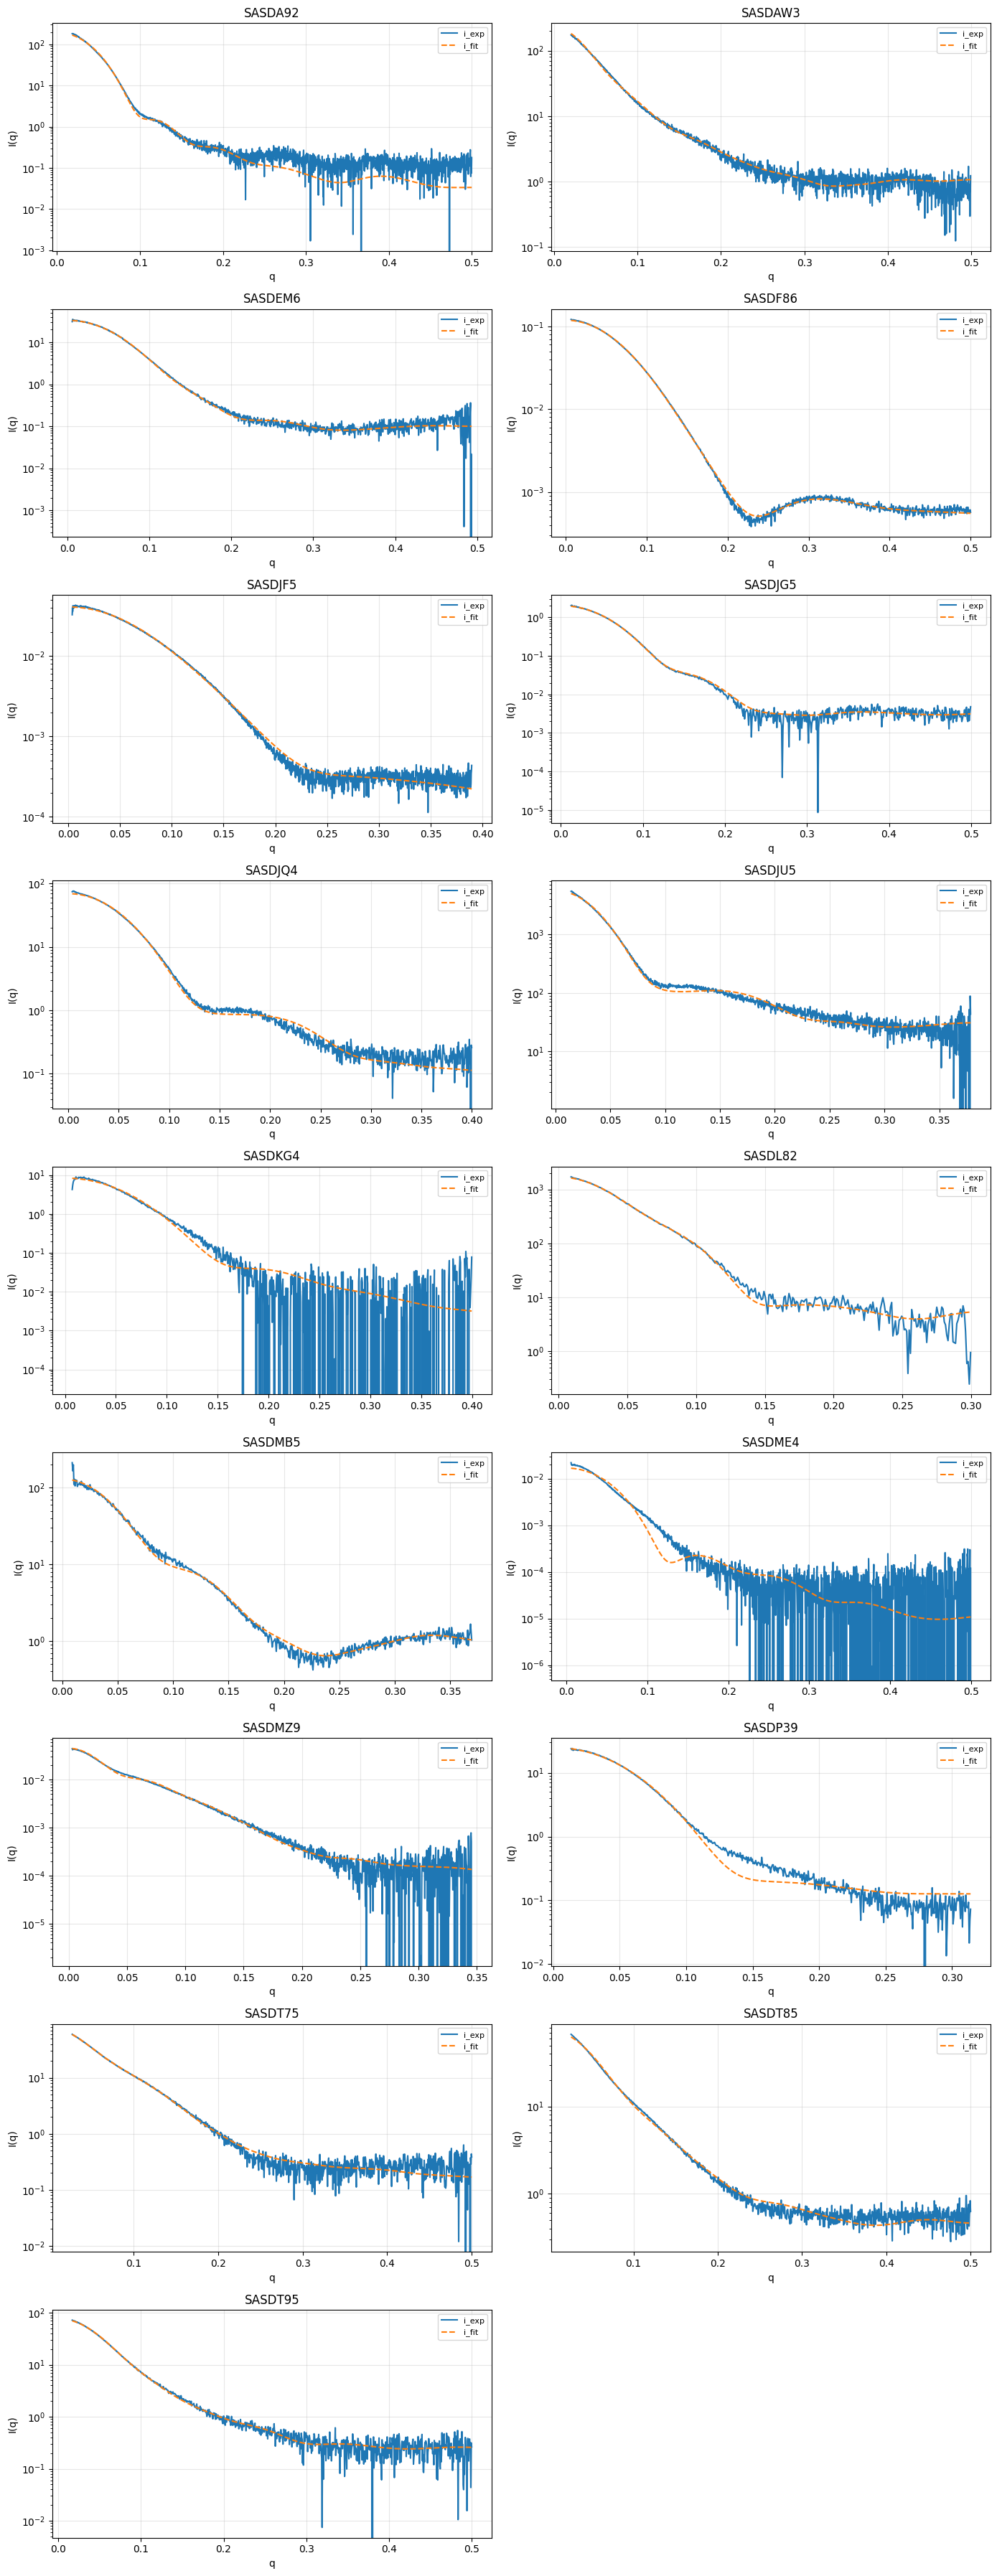

In [136]:
from pathlib import Path
import math
import pandas as pd

base_dir = Path("../../sasbdb_bench/cache")
csv_files = sorted(base_dir.glob("*/sba_fit_martini.csv"))

if not csv_files:
    raise FileNotFoundError(f"No matching files found under: {base_dir.resolve()}")

n = len(csv_files)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
axes = axes.ravel()

for ax, csv_path in zip(axes, csv_files):
    df = pd.read_csv(csv_path)
    num_df = df.select_dtypes(include=[np.number])
    print(num_df.columns)
    if num_df.shape[1] < 2:
        ax.set_title(csv_path.parent.name)
        ax.text(0.5, 0.5, "Not enough numeric columns to plot", ha="center", va="center")
        ax.axis("off")
        continue

    x = num_df.iloc[:, 0]
    for col in num_df.columns[1:-2]:  # Exclude last two columns (i_fit and sigma)
        ax.plot(x, num_df[col], label=col)
    ax.plot(x, num_df["i_fit"], label="i_fit", linestyle="--")

    ax.set_title(csv_path.parent.name)
    ax.set_xlabel(num_df.columns[0])
    ax.set_ylabel("I(q)")
    ax.grid(True, alpha=0.3)
    ax.set_yscale("log")
    ax.legend(fontsize=8)

for ax in axes[len(csv_files):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(base_dir / "sba_fits_grid.pdf")
plt.show()

[PosixPath('../../sasbdb_bench/cache/SASDAW3/sba_fit_grid.csv'), PosixPath('../../sasbdb_bench/cache/SASDJG5/sba_fit_grid.csv'), PosixPath('../../sasbdb_bench/cache/SASDME4/sba_fit_grid.csv'), PosixPath('../../sasbdb_bench/cache/SASDT95/sba_fit_grid.csv')]
4
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')


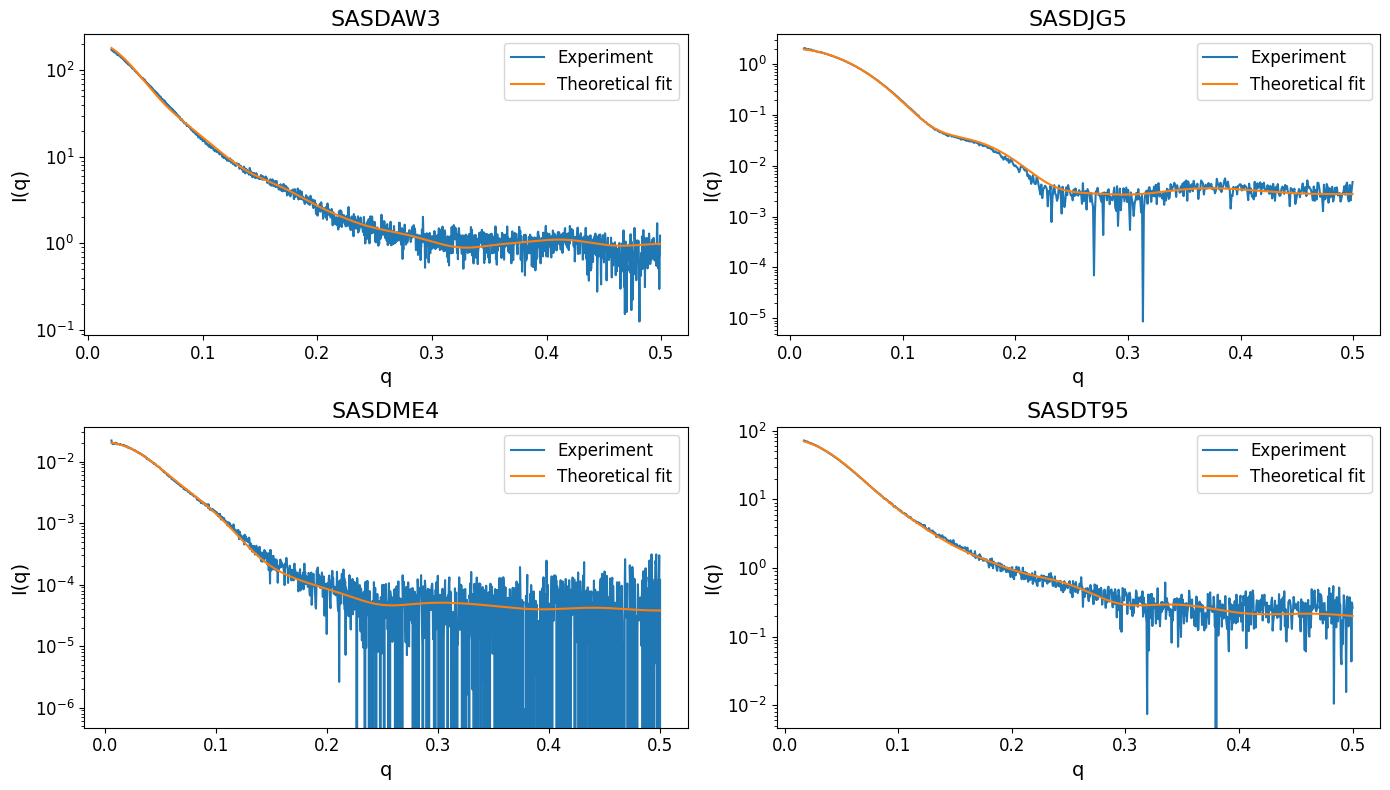

In [127]:
base_dir = Path("../../sasbdb_bench/cache")
csv_files = sorted(base_dir.glob("*/sba_fit_grid.csv"))

if not csv_files:
    raise FileNotFoundError(f"No matching files found under: {base_dir.resolve()}")

selected_indices = [ 1, 5, 11, -1]  # change these to the files you want
csv_files = [csv_files[i] for i in selected_indices]
print(csv_files)
n = len(csv_files)
print(n)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
axes = axes.ravel()

for ax, csv_path in zip(axes, csv_files):
    df = pd.read_csv(csv_path)
    num_df = df.select_dtypes(include=[np.number])
    print(num_df.columns)
    if num_df.shape[1] < 2:
        ax.set_title(csv_path.parent.name)
        ax.text(0.5, 0.5, "Not enough numeric columns to plot", ha="center", va="center")
        ax.axis("off")
        continue

    x = num_df.iloc[:, 0]
    for col in num_df.columns[1:-2]:  # Exclude last two columns (i_fit and sigma)
        ax.plot(x, num_df[col], label="Experiment")
    ax.plot(x, num_df["i_fit"], label="Theoretical fit", linestyle="-")

    ax.set_title(csv_path.parent.name, fontsize=16)
    ax.set_xlabel(num_df.columns[0], fontsize=14)
    ax.set_ylabel("I(q)", fontsize=14)
    #ax.grid(True, alpha=0.3)
    ax.set_yscale("log")
    ax.tick_params(axis="both", which="major", labelsize=12)
    ax.legend(fontsize=12)

for ax in axes[len(csv_files):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(base_dir / "sba_fits_grid.pdf")
plt.show()

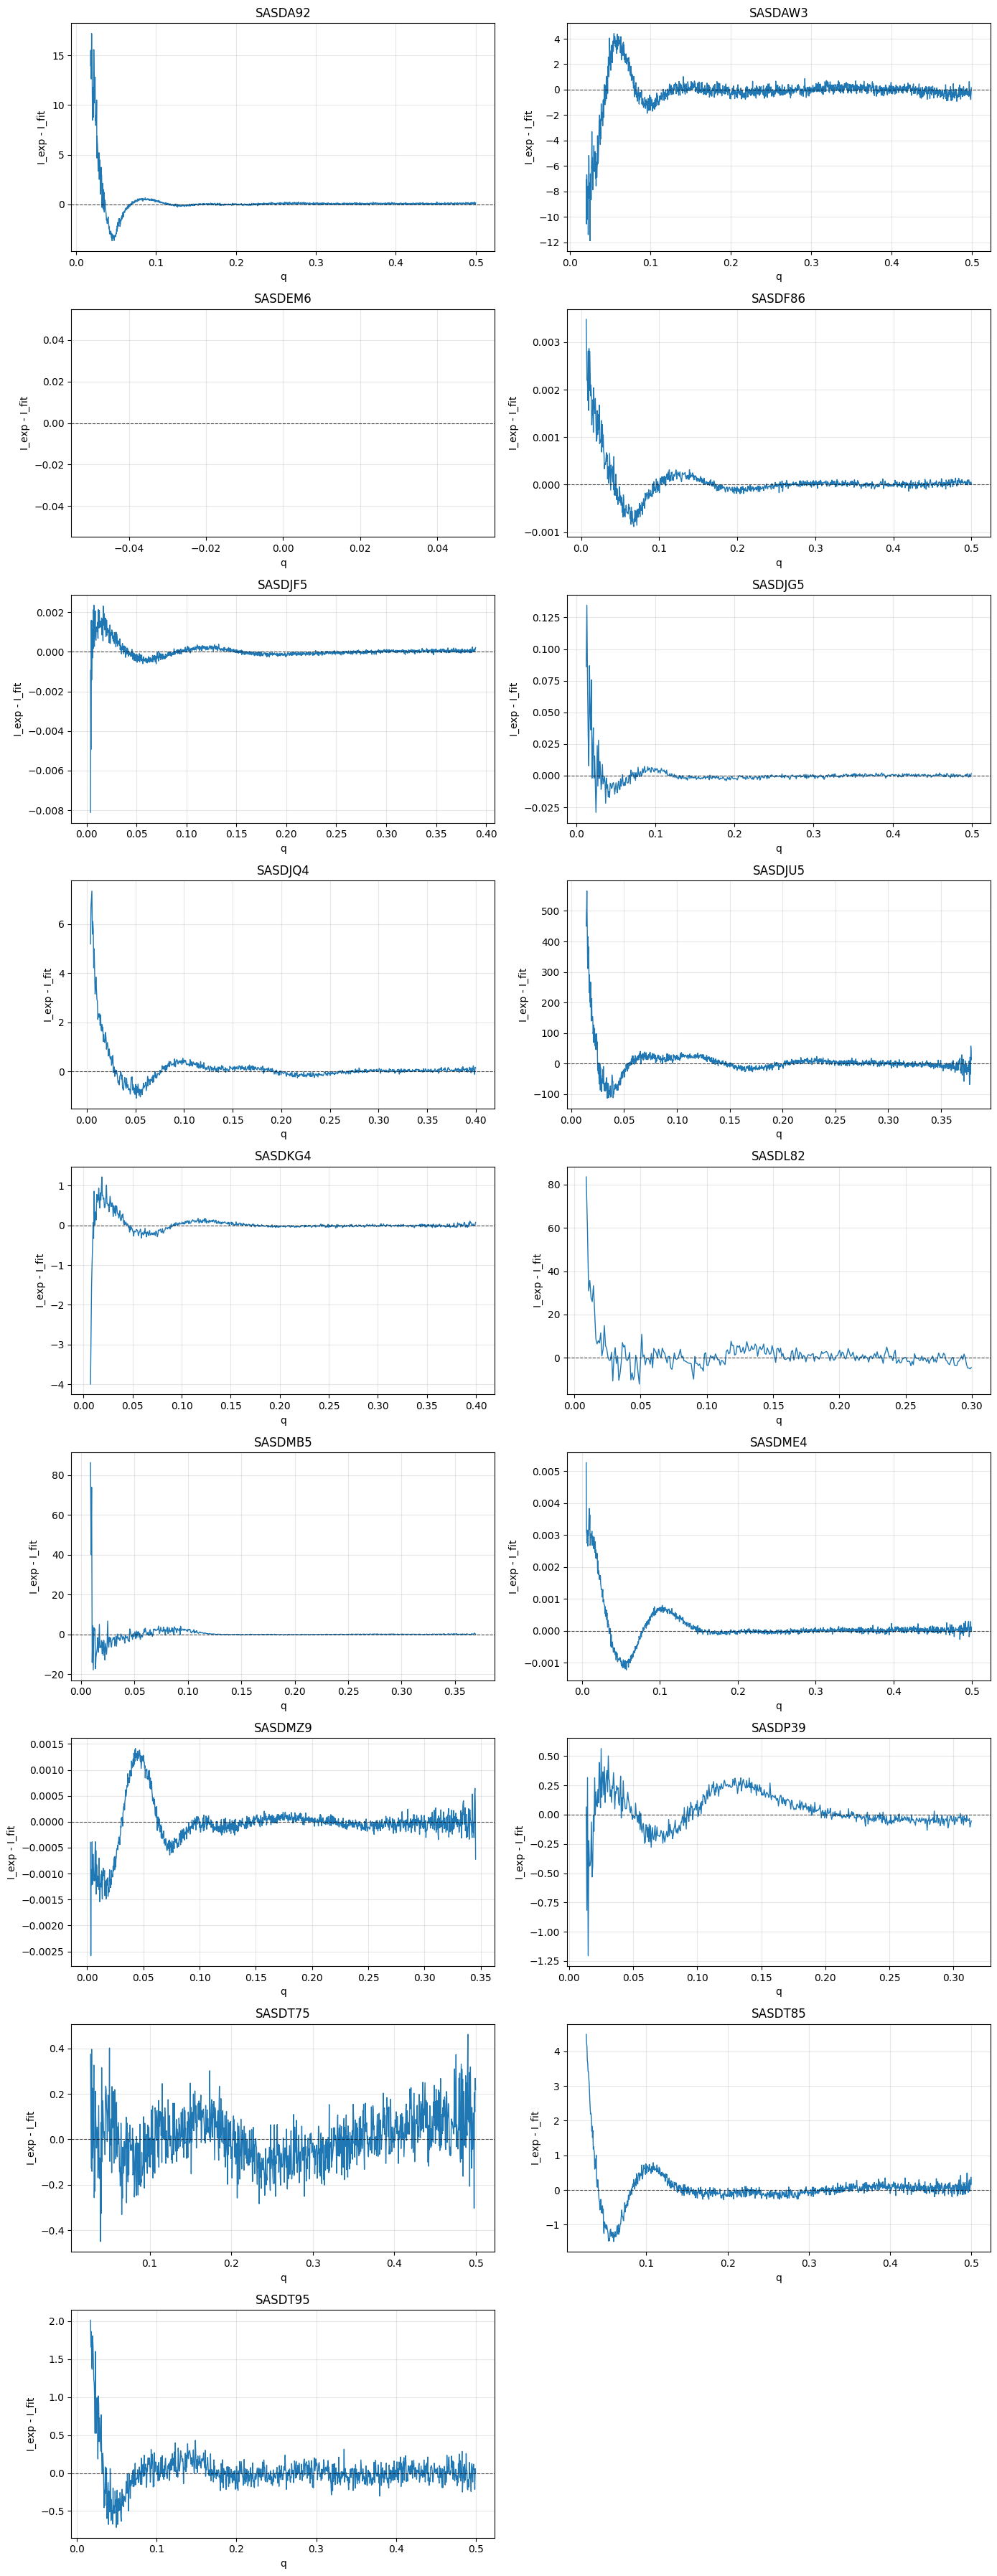

In [131]:
fig_res, axes_res = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
axes_res = axes_res.ravel()

for ax, csv_path in zip(axes_res, csv_files):
    tmp_df = pd.read_csv(csv_path)
    num_tmp = tmp_df.select_dtypes(include=[np.number])

    if not {"q", "i_exp", "i_fit"}.issubset(num_tmp.columns):
        ax.set_title(csv_path.parent.name)
        ax.text(0.5, 0.5, "Missing q/i_exp/i_fit columns", ha="center", va="center")
        ax.axis("off")
        continue

    residual = num_tmp["i_exp"] - num_tmp["i_fit"]

    ax.plot(num_tmp["q"], residual, lw=1)
    ax.axhline(0, color="black", ls="--", lw=0.8, alpha=0.7)
    ax.set_title(csv_path.parent.name)
    ax.set_xlabel("q")
    ax.set_ylabel("I_exp - I_fit")
    ax.grid(True, alpha=0.3)
    #ax.set_yscale("log")
    #ax.set_xscale("log")

for ax in axes_res[len(csv_files):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(base_dir / "sba_residuals_grid.pdf")
plt.show()

In [134]:
summary_path = base_dir / "sba_summary_martini.csv"

if not summary_path.exists():
    raise FileNotFoundError(f"File not found: {summary_path.resolve()}")

summary_df = pd.read_csv(summary_path, usecols=range(4))
#summary_df = pd.read_csv(summary_path)


print(np.mean(summary_df['chi2_per_point']))

7.977486467715632


In [135]:
summary_df

,sid,c1,c2,chi2_per_point
0,SASDA92,0.596778,0.032065,11.965604
1,SASDAW3,1.125131,-0.002186,7.996393
2,SASDEM6,1.095365,0.051917,5.844511
3,SASDF86,1.070153,0.032406,5.537906
4,SASDJF5,0.946732,0.035195,5.696015
5,SASDJG5,0.999408,0.032643,3.203928
6,SASDJQ4,0.590201,0.018454,10.100352
7,SASDJU5,1.228898,0.020755,4.149262
8,SASDKG4,0.918668,0.543583,5.618287
9,SASDL82,1.147741,0.015549,2.520915


In [112]:
4/3 *np.pi *1.009**3

4.302908469963444